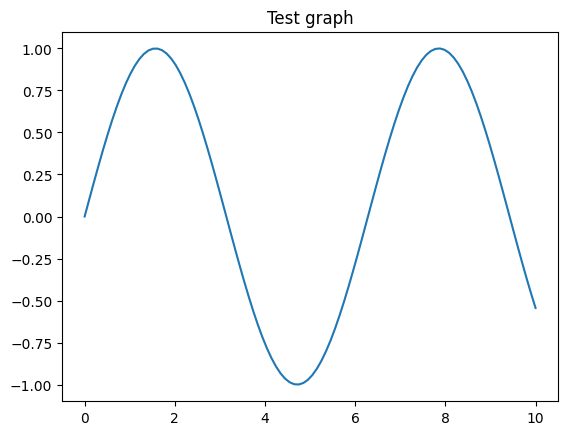

In [52]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 100)
plt.plot(x, np.sin(x))
plt.title("Test graph")
plt.show()

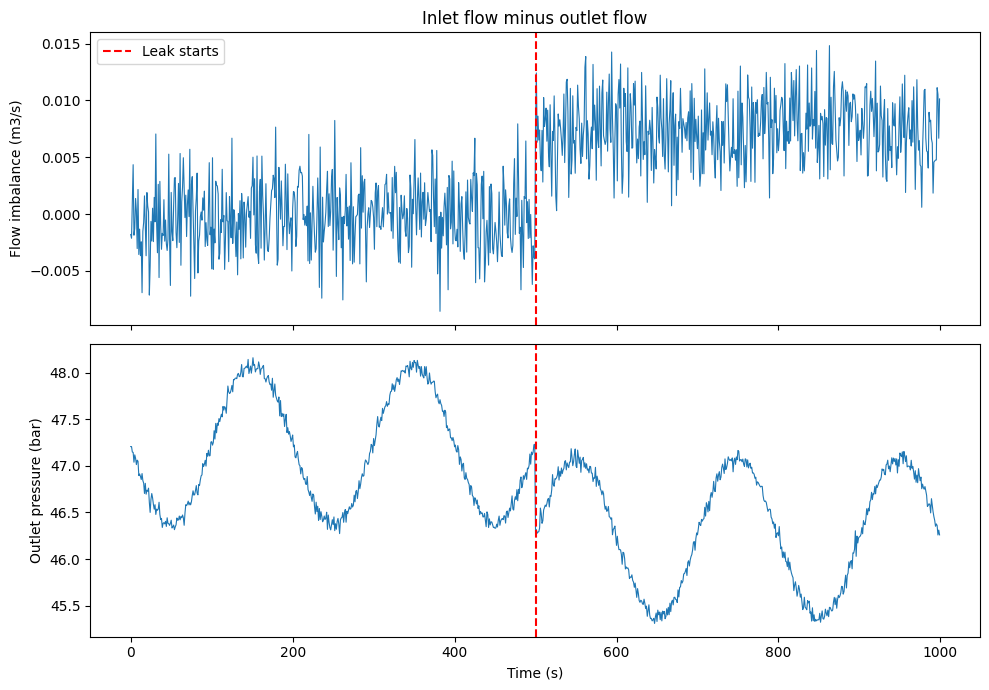

In [53]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ---- Pipe parameters (approximate, cite sources later) ----
L = 10000        # length, m
D = 0.3          # diameter, m
rho = 850        # oil density, kg/m3
f = 0.02         # friction factor
P_in = 60e5      # inlet pressure, Pa
A = np.pi * (D / 2) ** 2

T = 1000
t = np.arange(T)


def simulate_pipeline(t, q_nominal=0.15, flow_var=0.005):
    q_in = q_nominal + flow_var * np.sin(2 * np.pi * t / 200)
    v = q_in / A
    dp = f * (L / D) * (rho * v**2 / 2)
    p_in = np.full(len(t), P_in)
    p_out = p_in - dp
    return q_in, p_in, p_out


def add_noise(x, sigma):
    return x + np.random.normal(0, sigma, size=x.shape)


def inject_leak(q_in, p_out, start, size):
    q_out = q_in.copy()
    p_out = p_out.copy()
    q_out[start:] = q_in[start:] * (1 - size)
    p_out[start:] -= size * 20e5
    return q_out, p_out


q_in, p_in, p_out = simulate_pipeline(t)

LEAK_START = 500
LEAK_SIZE = 0.05
q_out, p_out_leak = inject_leak(q_in, p_out, LEAK_START, LEAK_SIZE)

q_in_m = add_noise(q_in, 0.002)
q_out_m = add_noise(q_out, 0.002)
p_out_m = add_noise(p_out_leak, 0.05e5)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(t, q_in_m - q_out_m, linewidth=0.8)
axes[0].axvline(LEAK_START, color="red", linestyle="--", label="Leak starts")
axes[0].set_ylabel("Flow imbalance (m3/s)")
axes[0].set_title("Inlet flow minus outlet flow")
axes[0].legend()

axes[1].plot(t, p_out_m / 1e5, linewidth=0.8)
axes[1].axvline(LEAK_START, color="red", linestyle="--")
axes[1].set_ylabel("Outlet pressure (bar)")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

False alarms before leak: 9
First alarm after leak: t = 500 s
Detection delay: 0 s


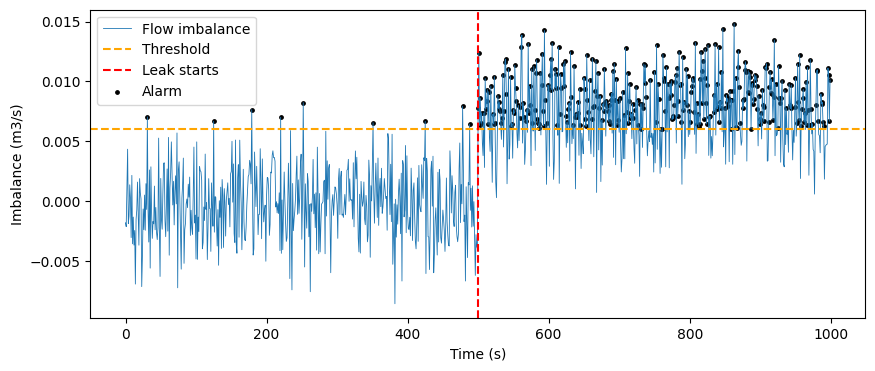

In [54]:
# ---- Detector 1: simple threshold ----
imbalance = q_in_m - q_out_m

THRESHOLD = 0.006   # m3/s, change this and re-run

alarm = imbalance > THRESHOLD
alarm_times = np.where(alarm)[0]

false_alarms = alarm_times[alarm_times < LEAK_START]
after_leak = alarm_times[alarm_times >= LEAK_START]

print(f"False alarms before leak: {len(false_alarms)}")
if len(after_leak) > 0:
    print(f"First alarm after leak: t = {after_leak[0]} s")
    print(f"Detection delay: {after_leak[0] - LEAK_START} s")
else:
    print("Leak NOT detected")

plt.figure(figsize=(10, 4))
plt.plot(t, imbalance, linewidth=0.6, label="Flow imbalance")
plt.axhline(THRESHOLD, color="orange", linestyle="--", label="Threshold")
plt.axvline(LEAK_START, color="red", linestyle="--", label="Leak starts")
plt.scatter(alarm_times, imbalance[alarm_times], color="black", s=6, label="Alarm")
plt.xlabel("Time (s)")
plt.ylabel("Imbalance (m3/s)")
plt.legend()
plt.show()

In [55]:
print("Threshold | Detection rate | False alarm rate")
for th in [0.004, 0.006, 0.008, 0.010]:
    alarm = imbalance > th
    dr = alarm[LEAK_START:].mean() * 100
    fr = alarm[:LEAK_START].mean() * 100
    print(f"{th:.3f}     | {dr:6.1f}%        | {fr:5.1f}%")

Threshold | Detection rate | False alarm rate
0.004     |   87.6%        |   6.4%
0.006     |   69.2%        |   1.8%
0.008     |   42.8%        |   0.2%
0.010     |   20.6%        |   0.0%


Window | Threshold | Detection rate | False alarm rate
     5 | 0.004     |   99.4%        |   0.0%
     5 | 0.005     |   96.8%        |   0.0%
     5 | 0.006     |   86.2%        |   0.0%
    10 | 0.004     |   98.8%        |   0.0%
    10 | 0.005     |   98.4%        |   0.0%
    10 | 0.006     |   93.4%        |   0.0%
    20 | 0.004     |   97.4%        |   0.0%
    20 | 0.005     |   97.0%        |   0.0%
    20 | 0.006     |   96.6%        |   0.0%


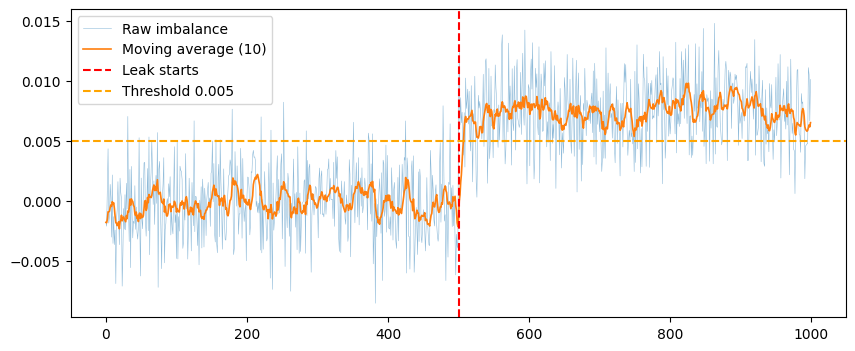

In [56]:
# ---- Detector 2: moving average ----
def moving_average(x, window):
  kernel = np.ones(window) / window
  return np.convolve(
      np.pad(x, (window - 1, 0), mode="edge"), kernel, mode="valid"
  )


print("Window | Threshold | Detection rate | False alarm rate")
for window in 5, 10, 20:
  smooth = moving_average(imbalance, window)
  for th in 0.004, 0.005, 0.006:
    alarm = smooth > th
    dr = alarm[LEAK_START:].mean() * 100
    fr = alarm[:LEAK_START].mean() * 100
    print(f"{window:6d} | {th:.3f}     | {dr:6.1f}%        | {fr:5.1f}%")

smooth = moving_average(imbalance, 10)
plt.figure(figsize=(10, 4))
plt.plot(t, imbalance, linewidth=0.4, alpha=0.5, label="Raw imbalance")
plt.plot(t, smooth, linewidth=1.2, label="Moving average (10)")
plt.axvline(LEAK_START, color="red", linestyle="--", label="Leak starts")
plt.axhline(0.005, color="orange", linestyle="--", label="Threshold 0.005")
plt.legend()
plt.show()


In [57]:
# run 100 time
dr_list, fr_list, delay_list = [], [], []

for seed in range(100):
  np.random.seed(seed)
  q_in, p_in, p_out = simulate_pipeline(t)
  q_out, p_out_leak = inject_leak(q_in, p_out, LEAK_START, LEAK_SIZE)

  imb = add_noise(q_in, 0.002) - add_noise(q_out, 0.002)
  smooth = moving_average(imb, window=10)
  alarm = smooth > 0.005

  dr_list.append(alarm[LEAK_START:].mean() * 100)
  fr_list.append(alarm[:LEAK_START].mean() * 100)

  if np.any(alarm[LEAK_START:]):
    delay_list.append(np.argmax(alarm[LEAK_START:]))

print('=== 100 Runs Average Results ===')
print(f'Avg Detection Rate   : {np.mean(dr_list):.2f}%')
print(f'Avg False Alarm Rate : {np.mean(fr_list):.2f}%')
print(f'Avg Detection Delay  : {np.mean(delay_list):.1f} seconds')


=== 100 Runs Average Results ===
Avg Detection Rate   : 98.41%
Avg False Alarm Rate : 0.01%
Avg Detection Delay  : 6.4 seconds


In [58]:
print(f'Missed leaks: {100 - len(delay_list)} of 100 runs')

Missed leaks: 0 of 100 runs


In [59]:
# small leak test: same 100-run Monte Carlo, different leak sizes
def monte_carlo(leak_size, n_runs=100, window=10, th=0.005):
    dr_list, fr_list, delay_list = [], [], []
    for seed in range(n_runs):
        np.random.seed(seed)
        q_in, p_in, p_out = simulate_pipeline(t)
        q_out, p_out_leak = inject_leak(q_in, p_out, LEAK_START, leak_size)

        imb = add_noise(q_in, 0.002) - add_noise(q_out, 0.002)
        smooth = moving_average(imb, window)
        alarm = smooth > th

        dr_list.append(alarm[LEAK_START:].mean() * 100)
        fr_list.append(alarm[:LEAK_START].mean() * 100)
        if np.any(alarm[LEAK_START:]):
            delay_list.append(np.argmax(alarm[LEAK_START:]))

    missed = n_runs - len(delay_list)
    delay = np.mean(delay_list) if delay_list else float("nan")
    return np.mean(dr_list), np.mean(fr_list), delay, missed

print("Leak | Detection | False alarm | Delay (s) | Missed of 100")
for size in [0.01, 0.02, 0.03, 0.05, 0.10]:
    dr, fr, dl, miss = monte_carlo(size)
    print(f"{size*100:3.0f}% | {dr:7.1f}%  | {fr:8.2f}%  | {dl:8.1f}  | {miss}")

Leak | Detection | False alarm | Delay (s) | Missed of 100
  1% |     0.0%  |     0.01%  |      nan  | 100
  2% |     1.3%  |     0.01%  |    153.0  | 9
  3% |    28.7%  |     0.01%  |     20.7  | 0
  5% |    98.4%  |     0.01%  |      6.4  | 0
 10% |    99.4%  |     0.01%  |      3.0  | 0
